In [1]:
import json
import yaml
import pandas as pd
import torch

from pytorch_lightning import Trainer
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping
from pytorch_lightning.loggers import CSVLogger

from dataset.tracking_datamodule import TrackingDataModule
from models.transformer_model import TrackingTransformer

ALL_VIDEOS = [
    # ('session0', 'center'),
    # ('session0', 'left'),
    # ('session0', 'right'),
    ('session1', 'center'),
    # ('session1', 'left'),
    # ('session1', 'right'),
    ('session2', 'center'),
    # ('session2', 'left'),
    # ('session2', 'right'),
    ('session3', 'center'),
    # ('session3', 'left'),
    # ('session3', 'right'),
    ('session4', 'center'),
    # ('session4', 'left'),
    # ('session4', 'right'),
    ('session5', 'center'),
    # ('session5', 'left'),
    # ('session5', 'right'),
    # ('session6', 'center'),
    # ('session6', 'left'),
    # ('session6', 'right'),
]

In [2]:
data_list = []
for session, recording in ALL_VIDEOS:
    with open(f'../../results/{session}_{recording}/tracked_cars_data.json', 'r') as f:
        cars = json.load(f)['cars']
        valid_cars = list(filter(lambda car: car['gt_speed'] is not None, cars))
        data_list.extend(valid_cars)


In [3]:
data_module = TrackingDataModule(
    data_list=data_list,
    batch_size=4,
    split_ratio=(0.8, 0.1, 0.1),
    num_workers=4
)

# Modelo
model = TrackingTransformer(
    input_size=4,
    d_model=128,
    nhead=4,
    dim_feedforward=256,
    num_layers=3,
    dropout=0.1,
    lr=1e-3,
    max_len=200,
)

# Callbacks y logger
logger = CSVLogger("logs/", name="tracking_transformer")
checkpoint_cb = ModelCheckpoint(
    save_top_k=1, mode='min', monitor='val_loss',
    dirpath='checkpoints/transformer', filename='best-transformer'
)
earlystop_cb = EarlyStopping(monitor='val_loss', patience=7)
# tqdm_cb = TQDMProgressBar(leave=True)

trainer = Trainer(
    max_epochs=200,
    callbacks=[
        checkpoint_cb,
        earlystop_cb,
        # tqdm_cb
    ],
    accelerator="auto",
    devices="auto",
    logger=logger,
    deterministic=False,
    log_every_n_steps=10,
)
trainer.fit(model, datamodule=data_module)
trainer.test(model, datamodule=data_module)

/usr/local/lib/python3.10/dist-packages/torch/nn/modules/transformer.py:306: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")
INFO:pytorch_lightning.utilities.rank_zero:Trainer will use only 1 of 4 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=4)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (5 outputs left out)

INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1,2,3]


Testing: |          | 0/? [00:00<?, ?it/s]

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_acc          │    0.8434709906578064     │
│         test_loss         │    230.94415283203125     │
│         test_mae          │    12.003153800964355     │
│         test_mse          │    230.94415283203125     │
└───────────────────────────┴───────────────────────────┘

[{'test_loss': 230.94415283203125,
  'test_mse': 230.94415283203125,
  'test_mae': 12.003153800964355,
  'test_acc': 0.8434709906578064}]

In [4]:
predictions = trainer.predict(model, dataloaders=data_module.test_dataloader())
pred_df = pd.DataFrame(predictions, columns=["pred", "target"])

INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1,2,3]


Predicting: |          | 0/? [00:00<?, ?it/s]

In [5]:
df_pred = pd.DataFrame(
    [
        (
            pred[i].item(),
            real[i].item(),
            abs(pred[i].item() - real[i].item())
        )
        for (pred, real) in predictions
        for i in range(len(pred))
    ],
    columns=["Velocidad Predicha", "Velocidad Real", "Error km/h"]
)
df_pred.head(20)

,Velocidad Predicha,Velocidad Real,Error km/h
0,85.492912,60.141602,25.351311
1,85.492882,70.153198,15.339684
2,85.492935,84.924004,0.568932
3,85.493172,119.059196,33.566025
4,85.492950,77.043602,8.449348
5,85.492950,81.802803,3.690147
6,85.492844,70.707603,14.785240
7,85.493187,87.641998,2.148811
8,85.492935,74.314796,11.178139
9,85.492859,70.336800,15.156059


KeyError: "['train_mse'] not in index"

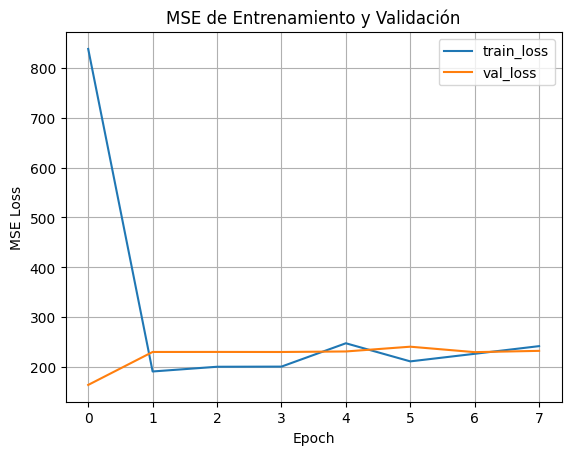

In [6]:
metrics = pd.read_csv(f"{trainer.logger.log_dir}/metrics.csv")

aggreg_metrics = []
agg_col = "epoch"
for i, dfg in metrics.groupby(agg_col):
    agg = dict(dfg.mean())
    agg[agg_col] = i
    aggreg_metrics.append(agg)

df_metrics = pd.DataFrame(aggreg_metrics)

df_metrics[["train_loss", "val_loss"]].plot(
    grid=True, 
    legend=True, 
    xlabel="Epoch",
    ylabel="MSE Loss", 
    # ylim=(0, 500),
    title="MSE de Entrenamiento y Validación", 
)

df_metrics[["train_mse", "val_mse"]].plot(
    grid=True, 
    legend=True, 
    xlabel="Epoch", 
    ylabel="RMSE",
    title="RMSE de Entrenamiento y Validación",
)

df_metrics[["train_mae", "val_mae"]].plot(
    grid=True, 
    legend=True, 
    xlabel="Epoch", 
    ylabel="MAE",
    title="MAE - Entrenamiento y Validación",
)

df_metrics[["train_acc", "val_acc"]].plot(
    grid=True, 
    legend=True, 
    xlabel="Epoch", 
    ylabel="Accuracy",
    title="Precisión Relativa de Entrenamiento y Validación",
)

plt.show()